# CSCI1409 Deep Learning, Week 7 SIS Mini-project 2
## CIFAR-10: your own CNN, Dropout, and why accuracy is not enough

SIS mini-project 2: 4 course points · Defense: in class, Week 7

This lab covers both Week 7 topics: regularization (Dropout) and model evaluation metrics.

Goal: design and code your own CNN for color images, train it twice (without and with Dropout), and check how good it really is with more than accuracy: precision, recall, F1, average precision (AP) and a confusion matrix. At the end you tune the decision threshold for the two rare classes.

One twist: in this lab cats and dogs are rare. Imagine an app where most photos show planes, cars, ships, birds or horses, and only a few show cats or dogs. You will find out how well your models work on these rare classes, and how much a better threshold can help.

The most important rule of this lab: every decision (which model is best, which threshold to use) is made on the validation set. The test set is used once, in section 8, after all decisions are made.

You work in groups of 3. Apart from the dataset download, all code in this notebook is written by your group. No ready-made or pretrained networks: you build the CNN yourselves from PyTorch layers. The cells only contain `# TODO` comments with hints. Every student must be able to explain every line and every plot. Write short answers in the answer cells (2 to 4 sentences each is enough), and every answer must use your own numbers.

Before class: make sure `torch`, `datasets` (Hugging Face), `matplotlib` and `scikit-learn` are installed ([PyTorch setup guide](https://pytorch.org/get-started/locally/), then `pip install datasets matplotlib scikit-learn`). The first download of CIFAR-10 from Hugging Face (about 144 MB) needs internet. A CPU is enough, no GPU needed. Training both models for 15 epochs takes roughly 10 to 30 minutes on a laptop CPU, depending on the size of your CNN, so do not start the night before. A GPU (for example free Google Colab) makes it faster but is not required.

### AI-use rule for this lab (Level C, AI-Assisted)

You may use generative AI to get ideas, explain concepts, debug code, or get feedback. However, your group must design the CNN and write the main solution yourselves, and understand and check everything you submit. At the defense you will explain your code, plots and metrics without AI help. "The AI wrote it" is not an answer.

Check AI explanations against the lectures and the PyTorch and scikit-learn documentation. A general definition without your own numbers does not count as an answer in this lab. Plagiarism, copying another group's code, and invented results are not allowed under any circumstances. If you used an external source (tutorial, blog, docs), name it in your answers.

## 1. Dataset

CIFAR-10 has 32×32 color images in 10 classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck. The download code is given: it loads the dataset [uoft-cs/cifar10](https://huggingface.co/datasets/uoft-cs/cifar10) from Hugging Face and gives you `full_train` (50,000 images) and `full_test` (10,000 images). Both work like `torchvision.datasets.CIFAR10`:
- `full_train[i]` gives `(image, label)`, where `image` is a float tensor of shape `[3, 32, 32]` with values from 0 to 1, and `label` is an int from 0 to 9
- `full_train.targets` is a list with the label of every image
- `full_train.classes` is the list of class names, in label order

You build three sets with the sizes below. Cats (class 3) and dogs (class 5) get 10 times fewer images than the other classes, in all three sets.

| Set | Taken from | Each of the 8 other classes | Cat | Dog | Total |
|---|---|---|---|---|---|
| Train | official training portion | 1,000 | 100 | 100 | 8,200 |
| Validation | official training portion, images not used in train | 500 | 50 | 50 | 4,100 |
| Test | official test set | 1,000 | 100 | 100 | 8,200 |

The validation set is bigger than you may expect. In section 7 you use it to choose thresholds for cats and dogs, and with only a few cats that choice would be very noisy.

Key words:
- Training set: the images the model learns from.
- Validation set: images used to check the model during training and to make decisions (best model, thresholds).
- Test set: images used only once, at the very end, after all decisions are made. In this lab that is section 8.

In [1]:
# Offline version: load CIFAR-10 from the local copy in ../data/cifar-10-batches-py (no internet, no `datasets` package).
import os
import pickle
import numpy as np
import torch
from torch.utils.data import Dataset

DATA_ROOT = "../data/cifar-10-batches-py"


def load_batches(files):
    # read the pickled CIFAR-10 batch files -> uint8 array [N, 32, 32, 3] and a list of int labels
    xs, ys = [], []
    for f in files:
        with open(os.path.join(DATA_ROOT, f), "rb") as fh:
            d = pickle.load(fh, encoding="bytes")
        xs.append(d[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1))
        ys += list(d[b"labels"])
    return np.concatenate(xs), ys


class CIFAR10Local(Dataset):
    # One CIFAR-10 split. Works like torchvision.datasets.CIFAR10 with transforms.ToTensor().

    def __init__(self, files):
        self.images, self.targets = load_batches(files)    # [N, 32, 32, 3] uint8, list of ints
        with open(os.path.join(DATA_ROOT, "batches.meta"), "rb") as fh:
            self.classes = [n.decode() for n in pickle.load(fh, encoding="bytes")[b"label_names"]]

    def __len__(self):
        return len(self.targets)

    def __getitem__(self, i):
        # [32, 32, 3] uint8 in 0..255  ->  [3, 32, 32] float in 0..1
        image = torch.from_numpy(self.images[i]).permute(2, 0, 1).float() / 255.0
        return image, self.targets[i]


full_train = CIFAR10Local([f"data_batch_{i}" for i in range(1, 6)])
full_test = CIFAR10Local(["test_batch"])

print("Official training portion:", len(full_train), "images")
print("Official test set:", len(full_test), "images")
print("Classes:", full_train.classes)


Official training portion: 50000 images
Official test set: 10000 images
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [2]:
# TODO: import what you need (torch, torch.nn, DataLoader, Subset, matplotlib, numpy, sklearn.metrics)
# TODO: fix a random seed (e.g. torch.manual_seed(42)) so your results are repeatable
# TODO: pick the device: "cuda" if torch.cuda.is_available() else "cpu"
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    accuracy_score,
    average_precision_score
)

torch.manual_seed(42)
np.random.seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"

print(device)

cpu


You build three sets with the sizes below. Cats (class 3) and dogs (class 5) get 10 times fewer images than the other classes, in all three sets.

| Set | Taken from | Each of the 8 other classes | Cat | Dog | Total |
|---|---|---|---|---|---|
| Train | official training portion | 1,000 | 100 | 100 | 8,200 |
| Validation | official training portion, images not used in train | 500 | 50 | 50 | 4,100 |
| Test | official test set | 1,000 | 100 | 100 | 8,200 |

The validation set is bigger than you may expect. In section 7 you use it to choose thresholds for cats and dogs, and with only a few cats that choice would be very noisy.

Key words:
- Training set: the images the model learns from.
- Validation set: images used to check the model during training and to make decisions (best model, thresholds).
- Test set: images used only once, at the very end, after all decisions are made. In this lab that is section 8.

In [3]:
# TODO: build the train and val indices from full_train using the table above
#       hint: full_train.targets is a list with the label of every image
#       hint: for each class, shuffle its indices with torch.randperm, then take the first N for train and the next M for val
# TODO: build the test indices from full_test the same way
# TODO: wrap the indices with torch.utils.data.Subset and print the size of each set

train_ids = []
val_ids = []
test_ids = []

classes_dict = []


for class_id in range(10):
    if class_id == 3 or class_id == 5:
        n_train = 100
        n_val = 50
        n_test = 100
    else:
        n_train = 1000
        n_val = 500
        n_test = 1000

    class_ids = np.where(np.array(full_train.targets) == class_id)[0]
    order = torch.randperm(len(class_ids)).numpy()
    class_ids = class_ids[order]

    train_ids.extend(class_ids[:n_train])
    val_ids.extend(class_ids[n_train: n_train + n_val])

    test_class_ids = np.where(np.array(full_test.targets) == class_id)[0]
    order = torch.randperm(len(test_class_ids)).numpy()
    test_class_ids = test_class_ids[order]
    test_ids.extend(test_class_ids[:n_test])


train_set = Subset(full_train, train_ids)
val_set = Subset(full_train, val_ids)
test_set = Subset(full_test, test_ids)



In [4]:
print(f'Shape of train-set: {len(train_set)}')
print(f'Shape of val-set: {len(val_set)}')
print(f'Shape of test-set: {len(test_set)}')

Shape of train-set: 8200
Shape of val-set: 4100
Shape of test-set: 8200


airplane: train=1000, val=500, test=1000
automobile: train=1000, val=500, test=1000
bird: train=1000, val=500, test=1000
cat: train=100, val=50, test=100
deer: train=1000, val=500, test=1000
dog: train=100, val=50, test=100
frog: train=1000, val=500, test=1000
horse: train=1000, val=500, test=1000
ship: train=1000, val=500, test=1000
truck: train=1000, val=500, test=1000


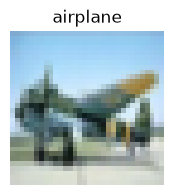

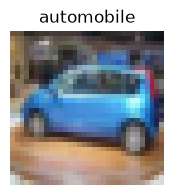

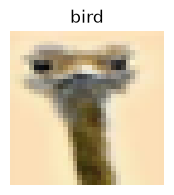

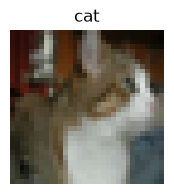

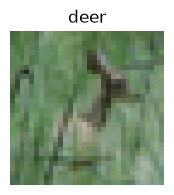

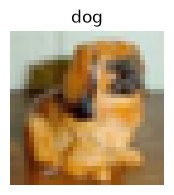

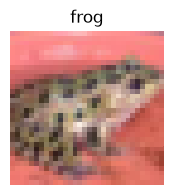

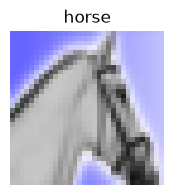

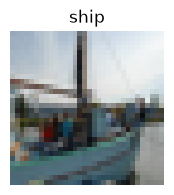

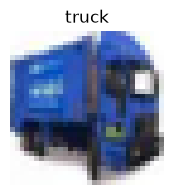

In [5]:
# TODO: count and print how many images of each class are in train, val and test, and check they match the table
# TODO: show one training image per class with its class name
#       hint: matplotlib needs the shape [32, 32, 3], so use image.permute(1, 2, 0)

train_labels = np.array([full_train.targets[index] for index in train_ids])
val_labels = [full_train.targets[index] for index in val_ids]
test_labels = [full_test.targets[index] for index in test_ids]



train_counts = np.bincount(train_labels, minlength=10)
val_counts = np.bincount(val_labels, minlength=10)
test_counts = np.bincount(test_labels, minlength=10)

for i in range(10):
    print(
        f"{full_train.classes[i]}: "
        f"train={train_counts[i]}, "
        f"val={val_counts[i]}, "
        f"test={test_counts[i]}"
    )



for class_id in range(10):
    for image, label in train_set:
        if class_id == label:
            plt.figure(figsize=(3,2))
            plt.imshow(image.permute(1,2,0))
            plt.title(full_train.classes[class_id])
            plt.axis("off")
            plt.show()
            break


#### Your answers: dataset

- What does the shape `[3, 32, 32]` mean? How is it different from FashionMNIST?
- What share of the test set are cats and dogs together?
- Why do we use the test set only once, at the end?

Write your answers here.

1 3 channels of rgb, heght/width 32 pixels, fashionmnist is gray scale images and has lower shape of 28x28
2 200/8200 =>1/41 * 100 means cat and dog only 2,44% of full tests set
3 we use it once because in trainset we only train model, then in valset we experiment with model by changing thresholds, experiment with hyperparameters and check wich give igher metrics. then on test set which model never seen make final matrics

## 2. Design your CNN

You design one CNN architecture and train it twice:
- Model A: your CNN without Dropout.
- Model B: exactly the same CNN with Dropout added. Nothing else changes.

Rules for your CNN:

| Rule | Requirement |
|---|---|
| Written by you | Build it from PyTorch layers: `nn.Conv2d`, `nn.ReLU`, `nn.MaxPool2d`, `nn.Flatten`, `nn.Linear`, `nn.Dropout`. Not allowed: `torchvision.models`, `timm`, pretrained weights, or a network copied from a tutorial. |
| Depth | 5 to 10 layers with weights. Count `Conv2d` and `Linear` layers together. ReLU, MaxPool, Flatten and Dropout have no weights, so they do not count. |
| Convolution | At least 3 `Conv2d` layers, each followed by `ReLU`. |
| Pooling | At least 2 `MaxPool2d` layers. |
| Classifier head | `Flatten`, then at least one hidden `Linear` layer with `ReLU`, then `Linear(…, 10)`. |
| Output | 10 logits. No softmax inside the model: `nn.CrossEntropyLoss` applies it for you. |

`nn.BatchNorm2d` is allowed if you can explain what it does, but it is not required.

An example that follows the rules (6 layers with weights). You may use it or design your own:

- Block 1: `Conv2d(3, 32, kernel_size=3, padding=1) → ReLU → Conv2d(32, 32, kernel_size=3, padding=1) → ReLU → MaxPool2d(2)`
- Block 2: `Conv2d(32, 64, kernel_size=3, padding=1) → ReLU → Conv2d(64, 64, kernel_size=3, padding=1) → ReLU → MaxPool2d(2)`
- Head: `Flatten → Linear(?, 256) → ReLU → Linear(256, 10)`

Finding the number in place of `?` for your own CNN is part of the task.

Dropout for Model B:
- Required: `nn.Dropout(p=0.5)` right after the hidden `ReLU`, before the output `Linear`.
- Recommended: also `nn.Dropout(p=0.25)` right after `Flatten`.
- You may try other places or values of `p`, but choose using the validation set and write down what you tried.

In [6]:
# TODO: write a function make_cnn(use_dropout) that builds your CNN as an nn.Module (or nn.Sequential)
#       use_dropout=False -> Model A, use_dropout=True -> Model B
#       one function for both models makes sure they cannot differ by accident
#       hint: nn.Conv2d, nn.ReLU, nn.MaxPool2d, nn.Flatten, nn.Linear, nn.Dropout

def make_cnn(use_dropout=False):
    layers = [ #3, 32,32
        nn.Conv2d(3,32,kernel_size=3,padding=1), # 32, 32, 32
        nn.ReLU(), # 32, 32, 32

        nn.Conv2d(32,32,kernel_size=3,padding=1), # 32, 32, 32
        nn.ReLU(), # 32, 32, 32
        nn.MaxPool2d(2), # 32, 16, 16

        nn.Conv2d(32,64,kernel_size=3,padding=1), # 64, 16, 16
        nn.ReLU(), # 64, 16, 16

        nn.Conv2d(64,64,kernel_size=3,padding=1), # 64, 16, 16
        nn.ReLU(), # 64, 16, 16
        nn.MaxPool2d(2), # 64, 8, 8
        nn.Flatten(),# 4096,
        nn.Linear(4096, 256), # 256
        nn.ReLU(), # 256
        

    ]

    if use_dropout:
        layers.append(nn.Dropout(p=0.5))

    layers.append(nn.Linear(256, 10))

    return nn.Sequential(*layers)


In [7]:
# TODO: pass a small batch through Model A and Model B and check the output shape is (batch_size, 10)
# TODO: print the output shape after every layer of your CNN
#       hint: loop over the layers of an nn.Sequential and apply them one by one
# TODO: count the layers with weights (Conv2d + Linear) and check every rule from the table
# TODO: count the trainable parameters of both models, and separately the parameters in conv layers and in linear layers
#       hint: sum(p.numel() for p in model.parameters())


fake_batch = torch.rand(4, 3, 32, 32)
model = make_cnn(use_dropout=False)
output = model(fake_batch)
print(f'Shape of output: {output.shape}')

x = fake_batch
total_num_params = 0
wgt_layer_conv = 0
wgt_layer_lin = 0
wgt_count = 0
for layer in model:
    x = layer(x)
    print(f"Shape of layer at {layer} : {x.shape}")


    num_params = sum(p.numel() for p in layer.parameters())
    total_num_params += num_params
    print(f'Number of Parameters: {num_params}\n')

    if isinstance(layer, nn.Conv2d):
        wgt_layer_conv += sum(p.numel() for p in layer.parameters())
        wgt_count+=1
    if isinstance(layer, nn.Linear):
        wgt_layer_lin += sum(p.numel() for p in layer.parameters())
        wgt_count+=1


print(f'Total Number of Parameters: {total_num_params}')
print(f'Total weighted parameters CONV: {wgt_layer_conv}')
print(f'Total weighted parameters LINEAR: {wgt_layer_lin}')
print(f'Total weighted layers: {wgt_count}')

Shape of output: torch.Size([4, 10])
Shape of layer at Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)) : torch.Size([4, 32, 32, 32])
Number of Parameters: 896

Shape of layer at ReLU() : torch.Size([4, 32, 32, 32])
Number of Parameters: 0

Shape of layer at Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)) : torch.Size([4, 32, 32, 32])
Number of Parameters: 9248

Shape of layer at ReLU() : torch.Size([4, 32, 32, 32])
Number of Parameters: 0

Shape of layer at MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False) : torch.Size([4, 32, 16, 16])
Number of Parameters: 0

Shape of layer at Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)) : torch.Size([4, 64, 16, 16])
Number of Parameters: 18496

Shape of layer at ReLU() : torch.Size([4, 64, 16, 16])
Number of Parameters: 0

Shape of layer at Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1)) : torch.Size([4, 64, 16, 16])
Number of Parameters: 36928

Shape o

#### Your answers: your CNN

- Write your architecture as a list of layers with the output shape after each one. How many layers with weights does it have?
- What number did you put in place of `?`, and how did you get it? Show how height and width change after every `Conv2d` and `MaxPool2d`.
- How many parameters does your CNN have in total, in the conv layers, and in the linear layers? Compute the parameters of one `Conv2d` layer by hand and check it against your code.
- Why do the conv layers need so few parameters? Think about what a 3×3 filter looks at, and that the same filter slides over the whole image.
- Why do Model A and Model B have exactly the same number of parameters? Why is there no softmax at the end of your model?

Write your answers here.

Conv rerquires fewer parameters, because it use shared parameters idea, so each filter goes again and again
Model A and Model B both have 1,116,970 parameters because Dropout has no trainable parameters. Their convolutional and linear layers are identical. There is no softmax at the end because CrossEntropyLoss expects raw logits and internally applies log-softmax.

## 3. Training setup

Use these settings for both models (you may change them, but write down what you used):

| Setting | Value |
|---|---|
| Optimizer | Adam |
| Learning rate | 0.001 |
| Batch size | 64 |
| Epochs | 15 |

Keep the seed, optimizer, learning rate, batch size and number of epochs the same for both models. Only Dropout changes, so the comparison is fair. We use 15 epochs so that overfitting has time to show up.

In [8]:
# TODO: create DataLoaders for train (shuffle=True), val and test (shuffle=False)
# TODO: choose a loss function for 10-class classification

train_loader=DataLoader(
    train_set,
    shuffle=True,
    batch_size=64
)
val_loader=DataLoader(
    val_set,
    shuffle=False,
    batch_size=64
)
test_loader=DataLoader(
    test_set,
    shuffle=False,
    batch_size=64
)


loss_fn = nn.CrossEntropyLoss()
epochs = 15
lr = 0.001


#### Your prediction (write it before training)

- Which model will reach the higher validation accuracy, and why?
- Which model will overfit more? What do you expect Dropout to change in the loss curves?
- Which classes do you think will be predicted worst?

Write your prediction here.

I expect Model B (with Dropout) to achieve higher validation accuracy because Dropout reduces reliance on individual neurons and may help prevent overfitting
I expect Model A to overfit more: its training loss may keep decreasing while its validation loss stops improving or increases. With Dropout, I expect Model B to have a smaller gap between training and validation loss
I expect cats and dogs to be predicted worst because the training set contains 10 times fewer examples of these classes than of each other class.

## 4. Training and evaluation code

You can reuse `train_one_epoch` and `evaluate` from SIS 1. Changes: move every batch to your device (`images.to(device)`, `labels.to(device)`), move each model to the device after you build it, and switch between train and eval mode correctly, because Dropout depends on it.

Key words:
- Overfitting: the training loss keeps going down, but the validation loss stops improving or goes up. The model memorises the training images instead of learning patterns that also work on new images.
- Regularization: any method that reduces overfitting. Dropout is one of them.
- Dropout with probability `p`: during training, every value that enters the Dropout layer is set to zero with probability `p`, independently for every image and every step. The network cannot rely on one single neuron, so it learns features that still work when some neurons are missing (Goodfellow et al., *Deep Learning*, Section 7.12).
- Inverted dropout: during training, PyTorch multiplies the values that are kept by `1 / (1 − p)`. Because of this, the average value is the same in training and in evaluation, and nothing needs to be rescaled at test time.
- `model.train()` and `model.eval()`: Dropout is active only in train mode. In eval mode it passes values through unchanged. So `train_one_epoch` must call `model.train()` and `evaluate` must call `model.eval()`. Forgetting this is one of the most common bugs with Dropout.

In [9]:
# TODO: write train_one_epoch(model, loader, loss_fn, optimizer)
#       start with model.train() so that Dropout is active
#       zero_grad -> forward -> loss -> backward -> step

def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()


    for image, label in loader:

        optimizer.zero_grad()

        output = model(image.to(device))

        loss = loss_fn(output, label.to(device))

        loss.backward()
        optimizer.step()





In [10]:
# TODO: write evaluate(model, loader, loss_fn) that returns (average loss, accuracy)
#       use model.eval() (this also switches Dropout off) and torch.no_grad()


def evaluate(model, loader, loss_fn):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, label in loader:
            
            images = images.to(device)
            label = label.to(device)

            output = model(images)

            prediction = output.argmax(dim=1)
            loss = loss_fn(output, label)

            total+= label.size(0)
            total_loss+= loss.item() * images.size(0)
            correct += (prediction == label).sum().item()

    return total_loss/total, correct/total

In [11]:
# TODO: write run_experiment(model) that:
#       - creates an Adam optimizer for this model
#       - for each epoch: train once, then evaluate on train and on val with evaluate()
#         (eval mode, so Dropout is off and the two losses can be compared)
#       - stores train loss and val loss for every epoch in two lists and returns them
#       - prints epoch number, train loss, val loss, val accuracy


def run_experiment(model):
    train_loss = []
    val_loss = []

    optimizer = torch.optim.Adam(model.parameters(),lr=lr )

    for epoch in range(epochs):
        train_one_epoch(model, train_loader, loss_fn, optimizer)

        train_epoch_loss, train_acc = evaluate(model, train_loader, loss_fn)

        val_epoch_loss, val_acc = evaluate(model, val_loader, loss_fn)

        print(
            f"Epoch {epoch + 1}: "
            f"train loss={train_epoch_loss:.4f}, "
            f"val loss={val_epoch_loss:.4f}, "
            f"val accuracy={val_acc:.4f}"
        )

        train_loss.append(train_epoch_loss)
        val_loss.append(val_epoch_loss)


    return train_loss, val_loss



## 5. Train both models

In [12]:
# TODO: reset the seed, build Model A (no Dropout), move it to the device, and run the experiment

torch.manual_seed(42)
np.random.seed(42)

model_a = make_cnn(use_dropout=False).to(device)
train_losses_a, val_losses_a = run_experiment(model_a)

Epoch 1: train loss=1.5664, val loss=1.5840, val accuracy=0.4078
Epoch 2: train loss=1.5025, val loss=1.5361, val accuracy=0.4373
Epoch 3: train loss=1.3236, val loss=1.3990, val accuracy=0.4939
Epoch 4: train loss=1.1270, val loss=1.2325, val accuracy=0.5649
Epoch 5: train loss=0.9841, val loss=1.1616, val accuracy=0.5837
Epoch 6: train loss=0.8660, val loss=1.0829, val accuracy=0.6076
Epoch 7: train loss=0.7823, val loss=1.0744, val accuracy=0.6110
Epoch 8: train loss=0.6441, val loss=1.0623, val accuracy=0.6439
Epoch 9: train loss=0.5018, val loss=1.0670, val accuracy=0.6498
Epoch 10: train loss=0.3344, val loss=1.0866, val accuracy=0.6710
Epoch 11: train loss=0.2647, val loss=1.2926, val accuracy=0.6561
Epoch 12: train loss=0.1903, val loss=1.3754, val accuracy=0.6454
Epoch 13: train loss=0.1156, val loss=1.5335, val accuracy=0.6539
Epoch 14: train loss=0.0737, val loss=1.7317, val accuracy=0.6551
Epoch 15: train loss=0.0845, val loss=1.7185, val accuracy=0.6454


In [13]:
# TODO: reset the seed, build Model B (with Dropout), move it to the device, and run the experiment

torch.manual_seed(42)
np.random.seed(42)

model_b = make_cnn(use_dropout=True).to(device)
train_losses_b, val_losses_b = run_experiment(model_b)

Epoch 1: train loss=1.6748, val loss=1.6883, val accuracy=0.3837
Epoch 2: train loss=1.4650, val loss=1.4958, val accuracy=0.4483
Epoch 3: train loss=1.3335, val loss=1.3696, val accuracy=0.4990
Epoch 4: train loss=1.2843, val loss=1.3405, val accuracy=0.5215
Epoch 5: train loss=1.1258, val loss=1.2076, val accuracy=0.5593
Epoch 6: train loss=1.0753, val loss=1.1755, val accuracy=0.5698
Epoch 7: train loss=0.9822, val loss=1.0965, val accuracy=0.6051
Epoch 8: train loss=0.9773, val loss=1.1267, val accuracy=0.5951
Epoch 9: train loss=0.8861, val loss=1.0673, val accuracy=0.6088
Epoch 10: train loss=0.8521, val loss=1.0750, val accuracy=0.6154
Epoch 11: train loss=0.8612, val loss=1.1458, val accuracy=0.6059
Epoch 12: train loss=0.6420, val loss=0.9826, val accuracy=0.6639
Epoch 13: train loss=0.5645, val loss=0.9616, val accuracy=0.6732
Epoch 14: train loss=0.5433, val loss=0.9637, val accuracy=0.6746
Epoch 15: train loss=0.4549, val loss=0.9467, val accuracy=0.6778


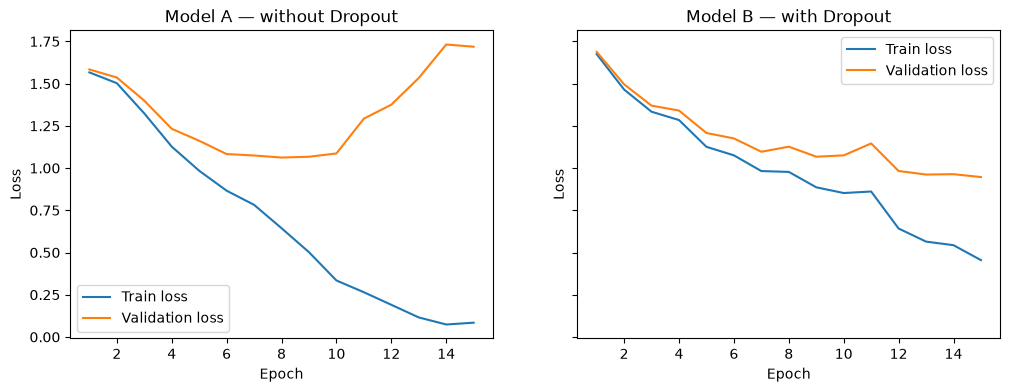

In [14]:
# TODO: plot train loss and val loss vs epoch for both models
#       (two panels side by side, same y-axis range; add a title, axis labels and a legend)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
epoch_numbers = range(1, epochs + 1)
axes[0].plot(epoch_numbers, train_losses_a, label="Train loss")
axes[0].plot(epoch_numbers, val_losses_a, label="Validation loss")
axes[1].plot(epoch_numbers, train_losses_b, label="Train loss")
axes[1].plot(epoch_numbers, val_losses_b, label="Validation loss")

axes[0].set_title("Model A — without Dropout")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].set_title("Model B — with Dropout")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

In [15]:
# TODO: Dropout experiment. Compute the validation accuracy of Model B three times:
#       once in eval mode, and twice in train mode (model.train(), still inside torch.no_grad())
#       hint: you cannot use evaluate() for the train-mode runs, because it switches to eval mode, so write a short loop
# TODO: print the three accuracies, then put Model B back in eval mode

def exp(model):
    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, label in val_loader:
            
            images = images.to(device)
            label = label.to(device)

            output = model(images)

            prediction = output.argmax(dim=1)
            loss = loss_fn(output, label)

            total+= label.size(0)
            total_loss+= loss.item() * images.size(0)
            correct += (prediction == label).sum().item()

    return total_loss/total, correct/total

model_b.eval()
_, acc_eval = exp(model_b)

model_b.train()
_, acc_train_1 = exp(model_b)
_, acc_train_2 = exp(model_b)

model_b.eval()

print(f"Eval:    {acc_eval:.2%}")
print(f"Train 1: {acc_train_1:.2%}")
print(f"Train 2: {acc_train_2:.2%}")





Eval:    67.78%
Train 1: 64.02%
Train 2: 64.12%


#### Your answers: loss curves and Dropout

- Give the final train loss and validation loss of both models. Which model has the lower validation loss?
- Does Model A overfit? If yes, from which epoch? Compare the gap between train and validation loss at the last epoch for Model A and Model B. What did Dropout change?
- Write the three accuracies from the Dropout experiment. Why is the train-mode accuracy lower, and why do the two train-mode runs give different numbers?
- If you print the loss of each batch during training (Dropout on), Model B's training loss can be higher than its validation loss. Why is this not a bug?
- Was your prediction right?

Write your answers here.

1. At epoch 15, Model A (without Dropout) had a training loss of **0.0845** and a validation loss of **1.7185**. Model B (with Dropout) had a training loss of **0.4549** and a validation loss of **0.9467**. Model B had the lower final validation loss. The minimum validation losses across all epochs were **1.0623** for A and **0.9467** for B.

2. Based on the loss curves, Model A appears to start overfitting around **epoch 11**: its training loss continues decreasing while its validation loss worsens. At the final epoch, the gap between validation and training loss was **1.6340** for A and **0.4918** for B. Dropout reduced this gap and helped Model B generalize better to unseen images.

3. Model B’s validation accuracies were **67.78% in eval mode**, **64.02% in the first train-mode run**, and **64.12% in the second**. Train-mode accuracy was lower because Dropout randomly removed some activations, making prediction harder. The two train-mode results differed because Dropout generated new random masks during each pass.

4. Model B’s training batch loss can be higher than its validation loss because Dropout is active during training but disabled during validation. Prediction can therefore be harder during training, even on familiar images. The losses are measured under different conditions, so this is not a bug.

5. My prediction was supported by the results: Model B achieved higher final validation accuracy (**67.78% vs 64.54%**), lower final validation loss, and a smaller train–validation loss gap. These results suggest that Dropout reduced overfitting. My prediction about cats and dogs still needs to be checked using per-class metrics.

## 6. Metrics on the validation set

Before you touch the test set, you compute all metrics on the validation set and use them to choose your best model. Write the metric functions once: in section 8 you use the same functions on the test set.

Key words, part 1 (one predicted class per image):
- Confusion matrix: a 10 × 10 table. Row = true class, column = predicted class. Cell `[i, j]` counts images of class `i` that the model predicted as class `j`.
- Precision of a class: of all images the model called "cat", how many really are cats. `precision = TP / (TP + FP)`
- Recall of a class: of all real cats, how many the model found. `recall = TP / (TP + FN)`
- F1 of a class: `2 · precision · recall / (precision + recall)`. It is high only when both are high.
- Macro F1: the plain average of the 10 per-class F1 scores. Every class counts the same.
- Weighted F1: the average of the per-class F1 scores, weighted by how many images each class has. Big classes count more.

Here TP (true positive) = real cat predicted as cat, FP (false positive) = not a cat but predicted as cat, FN (false negative) = real cat predicted as something else.

Key words, part 2 (scores and ranking):
- Score for class `c`: the softmax probability `p(c | image)`. A higher score means the model is more sure the image belongs to class `c`.
- Precision-recall (PR) curve: sort all images by their score for class `c`, highest first. Call the top `k` images "predicted c" and compute precision and recall. Every `k` gives one point (recall, precision).
- precision@k: the share of real class-`c` images among the top `k`.
- Average precision (AP) of class `c`: the average of precision@k over the ranks `k` where a real class-`c` image appears. `AP = (precision@k₁ + precision@k₂ + … + precision@k_P) / P`, where `P` is the number of real class-`c` images and `k₁, …, k_P` are their ranks. AP = 1.0 when all class-`c` images are ranked above all other images. AP uses no threshold: it measures how well the model ranks the images.
- Random baseline: a model that gives random scores gets AP of about the share of class `c` in the data. For a rare class this baseline is very small.
- Macro AP (also called mAP, mean average precision): the plain average of the 10 per-class APs.

Worked example for AP. Five images, sorted by their cat score:

| Rank k | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| Score for cat | 0.9 | 0.8 | 0.7 | 0.6 | 0.5 |
| Real cat? | yes | no | yes | no | no |
| precision@k | 1/1 | 1/2 | 2/3 | 2/4 | 2/5 |

The real cats are at ranks 1 and 3, so `AP = (1/1 + 2/3) / 2 = 0.833`. Your AP function must give 0.833 on this example.

In [16]:
# TODO: write get_predictions(model, loader) that returns three tensors:
#       true labels, predicted labels (argmax), and probabilities of shape [N, 10] (softmax of the logits)
#       use model.eval() and torch.no_grad()

def get_predictions(model, loader):
    true_labels = []
    predicted_labels = []
    probabilities = []
    model.eval()
    with torch.no_grad():
        for image, label in loader:
            image = image.to(device)
            output = model(image)
            prob = torch.softmax(output, dim=1)
            probabilities.append(prob)
            true_labels.append(label)
            predicted_labels.append(prob.argmax(dim=1))


    return (
        torch.cat(true_labels, dim=0),
        torch.cat(predicted_labels, dim=0),
        torch.cat(probabilities, dim=0),
    )


            



In [17]:
# TODO: build the 10 x 10 confusion matrix yourself from the true and predicted labels
# TODO: from the confusion matrix, compute precision, recall and F1 for every class
#       if no image is predicted as a class, use precision = 0 for that class
# TODO: compute accuracy, macro F1 and weighted F1


def confusion_matrix(true_labels, predicted_labels, probabilities):
    matrix = torch.zeros(10,10)
    for true, label in zip(true_labels, predicted_labels):
        matrix[true.item(), label.item()] += 1

    TP = matrix.diag()
    FP = matrix.sum(dim=0) - TP
    FN = matrix.sum(dim=1) - TP
    TN = matrix.sum() - TP - FN - FP

    precision = torch.zeros(10, dtype=torch.float64)
    recall = torch.zeros(10, dtype=torch.float64)
    f1 = torch.zeros(10, dtype=torch.float64)

    for c in range(10):
        tp = TP[c].item()
        fp = FP[c].item()
        fn = FN[c].item()

        if tp + fp > 0:
            precision[c] = tp / (tp + fp)

        if tp + fn > 0:
            recall[c] = tp / (tp + fn)

        if precision[c] + recall[c] > 0:
            f1[c] = (
                2 * precision[c] * recall[c]
                / (precision[c] + recall[c])
            )

    # Число настоящих изображений каждого класса.
    support = matrix.sum(dim=1)
    total = support.sum().item()

    accuracy = TP.sum().item() / total if total > 0 else 0.0
    macro_f1 = f1.mean().item()
    weighted_f1 = (
        (f1 * support).sum().item() / total if total > 0 else 0.0
    )

    return {
        "matrix": matrix,
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "TN": TN,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "support": support,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
    }
        

In [18]:
# TODO: write average_precision(is_positive, scores) yourself, following the definition above
#       is_positive: 1 for real class-c images, 0 for the rest; scores: the class-c probabilities
#       hint: sort by score (highest first), then use a cumulative sum of is_positive to get precision@k
# TODO: test it on the worked example: it must print 0.833
# TODO: compute AP for all 10 classes and the macro AP

def average_precision(is_positive, scores):
    is_positive = torch.as_tensor(is_positive).cpu().bool()
    scores = torch.as_tensor(scores).cpu()

    # Сортируем от самой высокой оценки к самой низкой.
    order = torch.argsort(scores, descending=True, stable=True)
    positives = is_positive[order]

    if positives.sum().item() == 0:
        return 0.0

    # Сколько настоящих представителей класса нашли к каждой позиции.
    cumulative_tp = positives.cumsum(dim=0)

    # Позиции: 1, 2, 3, ...
    ranks = torch.arange(1, len(positives) + 1)

    precision_at_k = cumulative_tp / ranks

    # Выбираем precision только там, где находится настоящий класс.
    return precision_at_k[positives].mean().item()

In [19]:
# TODO: apply your functions to the validation set for Model A and Model B
# TODO: print one table per model: one row per class with number of images, precision, recall, F1 and AP,
#       then accuracy, macro F1, weighted F1 and macro AP
# TODO: check your numbers with sklearn.metrics.classification_report and sklearn.metrics.average_precision_score,
#       they should match (tiny differences in AP can come from images with exactly the same score)
from sklearn.metrics import classification_report, average_precision_score

for name, model in [("Model A", model_a), ("Model B", model_b)]:
    true_labels, predicted_labels, probabilities = get_predictions(
        model, val_loader
    )

    # Переносим результаты на CPU для работы со sklearn.
    true_labels = true_labels.cpu()
    predicted_labels = predicted_labels.cpu()
    probabilities = probabilities.cpu()

    metrics = confusion_matrix(
        true_labels, predicted_labels, probabilities
    )

    ap_values = []
    sklearn_ap_values = []

    for c in range(10):
        is_positive = true_labels == c
        scores = probabilities[:, c]

        ap_values.append(average_precision(is_positive, scores))
        sklearn_ap_values.append(
            average_precision_score(is_positive.numpy(), scores.numpy())
        )

    macro_ap = sum(ap_values) / 10

    # Таблица нашей реализации.
    print(f"\n{name}")
    print(
        f"{'Class':12s} {'Count':>6s} {'Precision':>10s} "
        f"{'Recall':>8s} {'F1':>8s} {'AP':>8s}"
    )

    for c in range(10):
        print(
            f"{full_train.classes[c]:12s} "
            f"{metrics['support'][c].item():6f} "
            f"{metrics['precision'][c].item():10.3f} "
            f"{metrics['recall'][c].item():8.3f} "
            f"{metrics['f1'][c].item():8.3f} "
            f"{ap_values[c]:8.3f}"
        )

    print(f"Accuracy:    {metrics['accuracy']:.3f}")
    print(f"Macro F1:    {metrics['macro_f1']:.3f}")
    print(f"Weighted F1: {metrics['weighted_f1']:.3f}")
    print(f"Macro AP:    {macro_ap:.3f}")

    # Проверка precision, recall и F1 через sklearn.
    report = classification_report(
        true_labels.numpy(),
        predicted_labels.numpy(),
        labels=list(range(10)),
        target_names=full_train.classes,
        output_dict=True,
        zero_division=0,
    )

    for metric in ["precision", "recall", "f1"]:
        sklearn_key = "f1-score" if metric == "f1" else metric
        expected = [
            report[class_name][sklearn_key]
            for class_name in full_train.classes
        ]

        matches = np.allclose(metrics[metric].numpy(), expected)
        print(f"{metric} matches sklearn: {matches}")

    print(
        "Accuracy matches sklearn:",
        np.isclose(metrics["accuracy"], report["accuracy"]),
    )
    print(
        "Macro F1 matches sklearn:",
        np.isclose(metrics["macro_f1"], report["macro avg"]["f1-score"]),
    )
    print(
        "Weighted F1 matches sklearn:",
        np.isclose(
            metrics["weighted_f1"],
            report["weighted avg"]["f1-score"],
        ),
    )

    # При одинаковых scores способы обработки совпадений могут отличаться.
    ap_difference = np.abs(
        np.array(ap_values) - np.array(sklearn_ap_values)
    )
    print(f"Maximum AP difference from sklearn: {ap_difference.max():.6f}")




Model A
Class         Count  Precision   Recall       F1       AP
airplane     500.000000      0.540    0.746    0.626    0.709
automobile   500.000000      0.713    0.740    0.726    0.812
bird         500.000000      0.559    0.534    0.546    0.586
cat          50.000000      0.100    0.120    0.109    0.067
deer         500.000000      0.598    0.422    0.495    0.541
dog          50.000000      0.229    0.220    0.224    0.157
frog         500.000000      0.665    0.810    0.730    0.826
horse        500.000000      0.738    0.700    0.719    0.787
ship         500.000000      0.776    0.666    0.717    0.807
truck        500.000000      0.729    0.640    0.682    0.756
Accuracy:    0.645
Macro F1:    0.557
Weighted F1: 0.643
Macro AP:    0.605
precision matches sklearn: True
recall matches sklearn: True
f1 matches sklearn: True
Accuracy matches sklearn: True
Macro F1 matches sklearn: True
Weighted F1 matches sklearn: True
Maximum AP difference from sklearn: 0.000090

Model B
Cla

In [29]:
# TODO: choose your best model: the one with the highest validation macro AP. Store it in best_model and print which one it is
best_model = model_b
print("CHosed model_b ")


CHosed model_b 


#### Your answers: validation metrics

- Fill in for the validation set: | Model | accuracy | macro F1 | weighted F1 | macro AP |. Which model is your best model by macro AP? Do accuracy and macro F1 point to the same model?
- Why do we choose the best model on the validation set and not on the test set?

Write your answers here.

| Model | Accuracy | Macro F1 | Weighted F1 | Macro AP |
|---|---:|---:|---:|---:|
| A without Dropout | 0.645 | 0.557 | 0.643 | 0.605 |
| B with Dropout | 0.678 | 0.562 | 0.669 | 0.648 |

We select the model on the validation set because the model selection is part of the setup. We save the test set for the final independent evaluation: if we choose a model based on the test results, we will adjust to it, and the quality assessment may be overestimated.

## 7. Threshold search on the validation set

So far your prediction was argmax: the class with the highest probability wins. Now look at one rare class at a time as a yes/no question, "is this a cat?", and use a threshold `t`: predict cat if `p(cat) ≥ t`. A lower `t` gives more cat predictions: recall usually goes up and precision usually goes down. The threshold search finds a good balance. Use `best_model` and the validation set only.

Key words:
- Decision threshold `t`: the score from which we answer "yes, this is a cat".
- Operating point: one chosen `t` together with its precision and recall. It is one point on the PR curve.
- Why not simply `t = 0.5`? With 10 classes, the winning class often has a probability well below 0.5. So "`p(cat) ≥ 0.5`" can be much stricter than argmax. Check this in your numbers.

Choose two thresholds for cat and two for dog, on the validation set:

| Rule | How to choose `t` |
|---|---|
| Rule F1 | The `t` with the highest validation F1 for that class. Call it `t_F1`. |
| Rule R70 | The app team wants to find at least 70% of all cats (or dogs). Among the `t` with validation recall ≥ 0.70, take the one with the highest validation precision. Call it `t_R70`. If no `t` reaches 0.70, take the `t` with the highest recall and say so. |

Search over the grid `t = 0.01, 0.02, …, 0.99`.

In [38]:
# TODO: write prf_at_threshold(is_positive, scores, t) that returns (precision, recall, F1) for one class
#       an image is predicted positive if its score >= t; if no image is predicted positive, use precision = 0
# TODO: for cat and for dog: with best_model on the validation set, loop over the grid and store precision, recall and F1 for every t
# TODO: find t_F1 and t_R70 for cat and for dog, and print each one with its validation precision, recall and F1

def prf_at_threshold(is_positive, scores, t):
    predicted_postitve = scores >= t

    tp = (is_positive & predicted_postitve).sum().item()
    fp = (~is_positive & predicted_postitve).sum().item()
    fn = (is_positive & ~predicted_postitve).sum().item()
    tn = (~is_positive & ~predicted_postitve).sum().item()

    precision = 0
    recall = 0
    f1 = 0
    if tp + fp > 0:
        precision = tp/(tp+fp)
    if tp + fn > 0:
            recall = tp/(tp+fn)

    if precision + recall > 0:
         f1 = (2 * precision * recall)/(precision + recall)

    return precision, recall, f1
    

In [39]:
true_labels, _, probabilities = get_predictions(best_model, val_loader)

true_labels = true_labels.cpu()
probabilities = probabilities.cpu()

thresholds = np.arange(1, 100) / 100  # 0.01, ..., 0.99

results = {}

for c in [3, 5]:  # кошка и собака
    is_positive = true_labels == c
    scores = probabilities[:, c]

    precisions = []
    recalls = []
    f1s = []

    for t in thresholds:
        precision, recall, f1 = prf_at_threshold(is_positive, scores, t)

        precisions.append(precision)
        recalls.append(recall)
        f1s.append(f1)

    results[c] = {
        "precision": np.array(precisions),
        "recall": np.array(recalls),
        "f1": np.array(f1s),
    }



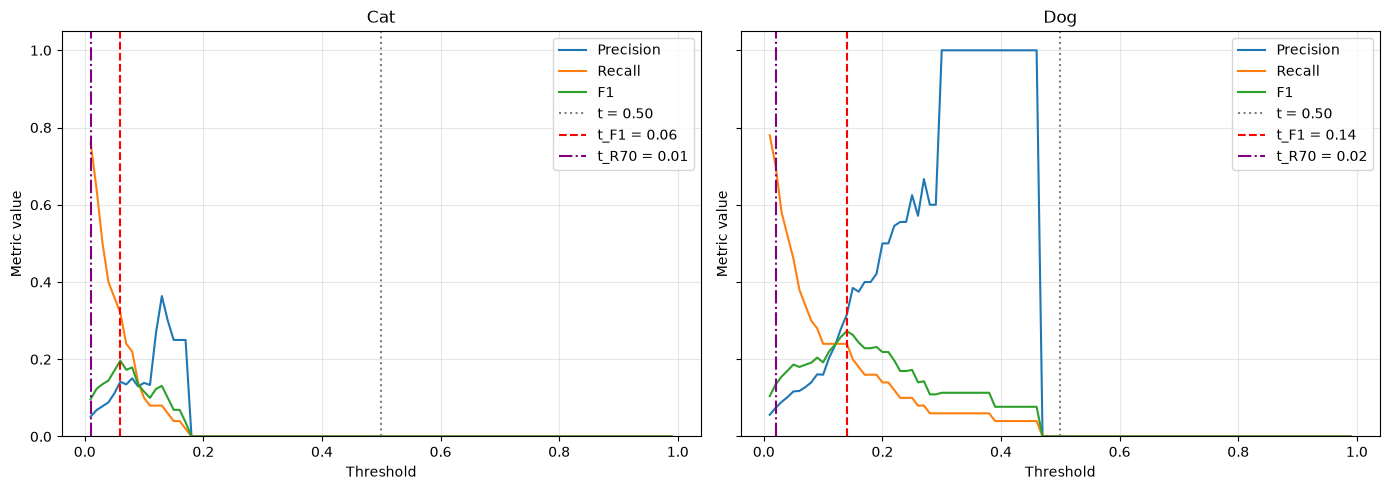

In [40]:
# TODO: plot precision, recall and F1 against t on the validation set (two panels: cat and dog)
#       add vertical lines at t = 0.5, t_F1 and t_R70, and a legend
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

for ax, c, name in zip(axes, [3, 5], ["Cat", "Dog"]):
    precision = results[c]["precision"]
    recall = results[c]["recall"]
    f1 = results[c]["f1"]

    # Порог с максимальным F1.
    idx_f1 = np.argmax(f1)
    t_f1 = thresholds[idx_f1]

    # Максимальный precision среди порогов с recall >= 0.70.
    candidates = np.where(recall >= 0.70)[0]

    if len(candidates) > 0:
        idx_r70 = candidates[np.argmax(precision[candidates])]
    else:
        idx_r70 = np.argmax(recall)
        print(f"{name}: recall 0.70 недостижим; выбран максимальный recall.")

    t_r70 = thresholds[idx_r70]

    results[c]["t_F1"] = t_f1
    results[c]["t_R70"] = t_r70

    ax.plot(thresholds, precision, label="Precision")
    ax.plot(thresholds, recall, label="Recall")
    ax.plot(thresholds, f1, label="F1")

    ax.axvline(0.5, color="gray", linestyle=":", label="t = 0.50")
    ax.axvline(
        t_f1, color="red", linestyle="--",
        label=f"t_F1 = {t_f1:.2f}"
    )
    ax.axvline(
        t_r70, color="purple", linestyle="-.",
        label=f"t_R70 = {t_r70:.2f}"
    )

    ax.set_title(name)
    ax.set_xlabel("Threshold")
    ax.set_ylabel("Metric value")
    ax.set_ylim(0, 1.05)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

#### Your answers: threshold search

- Write `t_F1` and `t_R70` for cat and dog. Are they above or below 0.5? Explain why, using what argmax does with 10 classes.
- From your plot: when `t` goes down, what happens to precision and to recall, and why? Why does F1 have a peak somewhere in the middle?
- By how much does validation recall for cat change when the model finds one more cat? What does this tell you about how exact your chosen thresholds are?

Write your answers here.

| Class | t_F1 | t_R70 |
|---|---:|---:|
| Cat | 0.06 | 0.01 |
| Dog | 0.14 | 0.02 |

All selected thresholds are below 0.5. With 10 classes, argmax selects the class with the highest probability, even if that probability is below 0.5. For example, a class can win with probability 0.25 if every other class has a lower probability. A threshold of 0.5 is too strict here: validation recall is zero for both cats and dogs.
As the threshold decreases, more images are predicted positive, so recall increases or stays the same. Precision generally decreases because the additional predictions include false positives, although it can fluctuate. In our plots, F1 peaks between the extreme thresholds because low thresholds produce many false positives, while high thresholds miss most real positives.
There are 50 cats in the validation set, so finding one additional cat increases recall by 1/50 = 0.02, or 2 percentage points. This makes recall change in noticeable steps. Our selected thresholds are the best values on the tested grid with a step of 0.01 for this validation set; they are not precise, universal values.

## 8. Final evaluation on the test set

All decisions are made. Now use the test set, once. Do not change your models, your choice of `best_model` or your thresholds after this point. If you do, say so in your answers.

In [41]:
# TODO: get predictions on the test set for Model A and Model B
# TODO: with your own metric functions, print one table per model
#       (per class: number of images, precision, recall, F1, AP; then accuracy, macro F1, weighted F1, macro AP)
# TODO: check your numbers with sklearn.metrics.classification_report and average_precision_score

from sklearn.metrics import classification_report, average_precision_score

test_results = {}

for name, model in [("Model A", model_a), ("Model B", model_b)]:
    true_labels, predicted_labels, probabilities = get_predictions(
        model, test_loader
    )

    true_labels = true_labels.cpu()
    predicted_labels = predicted_labels.cpu()
    probabilities = probabilities.cpu()

    metrics = confusion_matrix(
        true_labels, predicted_labels, probabilities
    )

    ap_values = []
    sklearn_ap_values = []

    for c in range(10):
        is_positive = true_labels == c
        scores = probabilities[:, c]

        ap_values.append(average_precision(is_positive, scores))
        sklearn_ap_values.append(
            average_precision_score(is_positive.numpy(), scores.numpy())
        )

    macro_ap = sum(ap_values) / 10

    # Сохраняем результаты, включая вероятности для следующих пунктов.
    test_results[name] = {
        "metrics": metrics,
        "ap": ap_values,
        "macro_ap": macro_ap,
        "true_labels": true_labels,
        "predicted_labels": predicted_labels,
        "probabilities": probabilities,
    }

    print(f"\n{name} — test set")
    print(
        f"{'Class':12s} {'Count':>6s} {'Precision':>10s} "
        f"{'Recall':>8s} {'F1':>8s} {'AP':>8s}"
    )

    for c in range(10):
        print(
            f"{full_train.classes[c]:12s} "
            f"{int(metrics['support'][c].item()):6d} "
            f"{metrics['precision'][c].item():10.3f} "
            f"{metrics['recall'][c].item():8.3f} "
            f"{metrics['f1'][c].item():8.3f} "
            f"{ap_values[c]:8.3f}"
        )

    print(f"Accuracy:    {metrics['accuracy']:.3f}")
    print(f"Macro F1:    {metrics['macro_f1']:.3f}")
    print(f"Weighted F1: {metrics['weighted_f1']:.3f}")
    print(f"Macro AP:    {macro_ap:.3f}")

    # Проверка через sklearn.
    report = classification_report(
        true_labels.numpy(),
        predicted_labels.numpy(),
        labels=list(range(10)),
        target_names=full_train.classes,
        output_dict=True,
        zero_division=0,
    )

    for metric in ["precision", "recall", "f1"]:
        key = "f1-score" if metric == "f1" else metric
        expected = [
            report[class_name][key]
            for class_name in full_train.classes
        ]

        print(
            f"{metric} matches sklearn:",
            np.allclose(metrics[metric].numpy(), expected),
        )

    print(
        "Accuracy matches sklearn:",
        np.isclose(metrics["accuracy"], report["accuracy"]),
    )
    print(
        "Macro F1 matches sklearn:",
        np.isclose(metrics["macro_f1"], report["macro avg"]["f1-score"]),
    )
    print(
        "Weighted F1 matches sklearn:",
        np.isclose(
            metrics["weighted_f1"],
            report["weighted avg"]["f1-score"],
        ),
    )

    ap_difference = np.abs(
        np.array(ap_values) - np.array(sklearn_ap_values)
    )
    print(f"Maximum AP difference from sklearn: {ap_difference.max():.6f}")


Model A — test set
Class         Count  Precision   Recall       F1       AP
airplane       1000      0.539    0.764    0.632    0.701
automobile     1000      0.739    0.726    0.733    0.804
bird           1000      0.562    0.522    0.541    0.576
cat             100      0.121    0.140    0.130    0.067
deer           1000      0.630    0.441    0.519    0.574
dog             100      0.192    0.140    0.162    0.119
frog           1000      0.644    0.806    0.716    0.795
horse          1000      0.707    0.700    0.704    0.773
ship           1000      0.765    0.636    0.695    0.782
truck          1000      0.678    0.618    0.646    0.708
Accuracy:    0.639
Macro F1:    0.548
Weighted F1: 0.636
Macro AP:    0.590
precision matches sklearn: True
recall matches sklearn: True
f1 matches sklearn: True
Accuracy matches sklearn: True
Macro F1 matches sklearn: True
Weighted F1 matches sklearn: True
Maximum AP difference from sklearn: 0.000983

Model B — test set
Class         Count

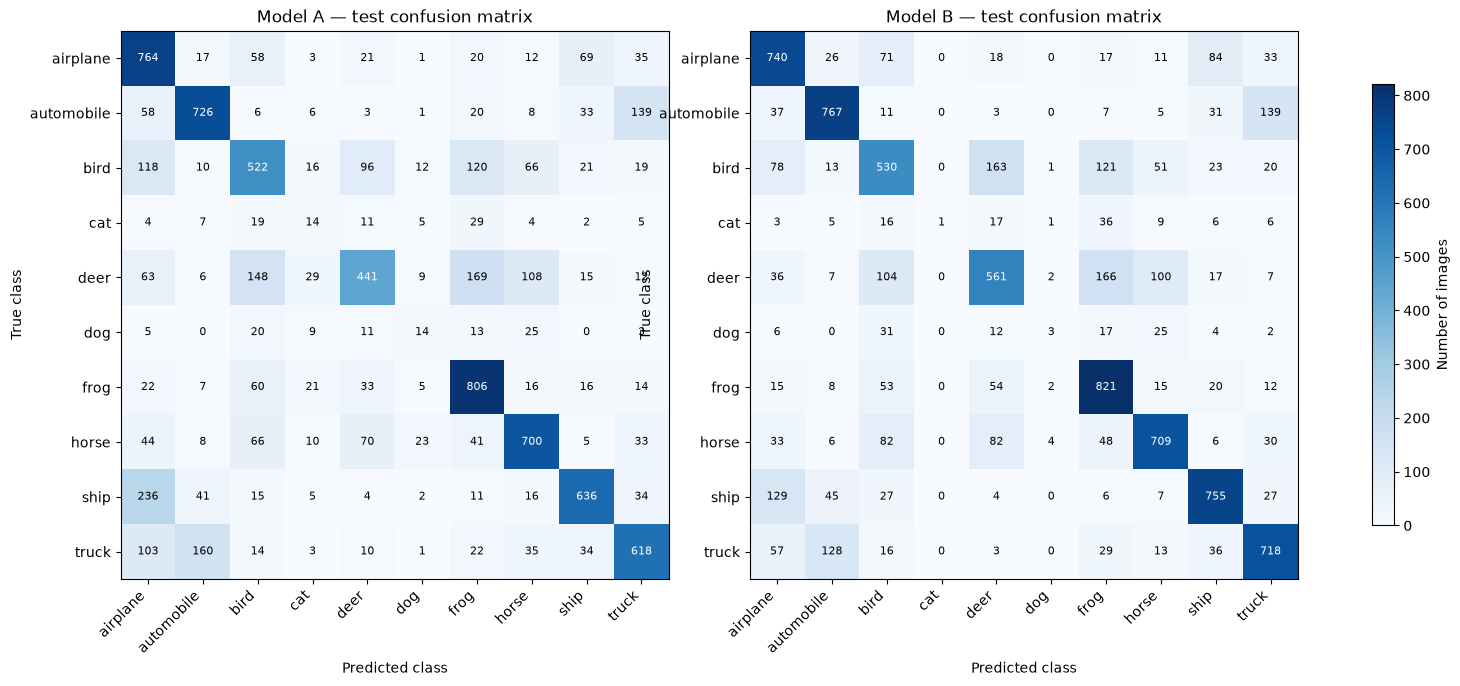

In [42]:
# TODO: plot the test confusion matrix of both models with class names on both axes
#       hint: plt.imshow, or sklearn.metrics.ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Общая цветовая шкала для обеих моделей.
vmax = max(
    test_results[name]["metrics"]["matrix"].max().item()
    for name in ["Model A", "Model B"]
)

for ax, name in zip(axes, ["Model A", "Model B"]):
    matrix = test_results[name]["metrics"]["matrix"].cpu().numpy()

    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=vmax)

    ax.set_xticks(range(10))
    ax.set_yticks(range(10))
    ax.set_xticklabels(full_train.classes, rotation=45, ha="right")
    ax.set_yticklabels(full_train.classes)

    ax.set_xlabel("Predicted class")
    ax.set_ylabel("True class")
    ax.set_title(f"{name} — test confusion matrix")

    # Количество изображений в каждой ячейке.
    for row in range(10):
        for col in range(10):
            ax.text(
                col, row, str(int(matrix[row, col])),
                ha="center",
                va="center",
                color="white" if matrix[row, col] > vmax / 2 else "black",
                fontsize=8,
            )

fig.tight_layout()
fig.colorbar(image, ax=axes, label="Number of images", shrink=0.8)
plt.show()

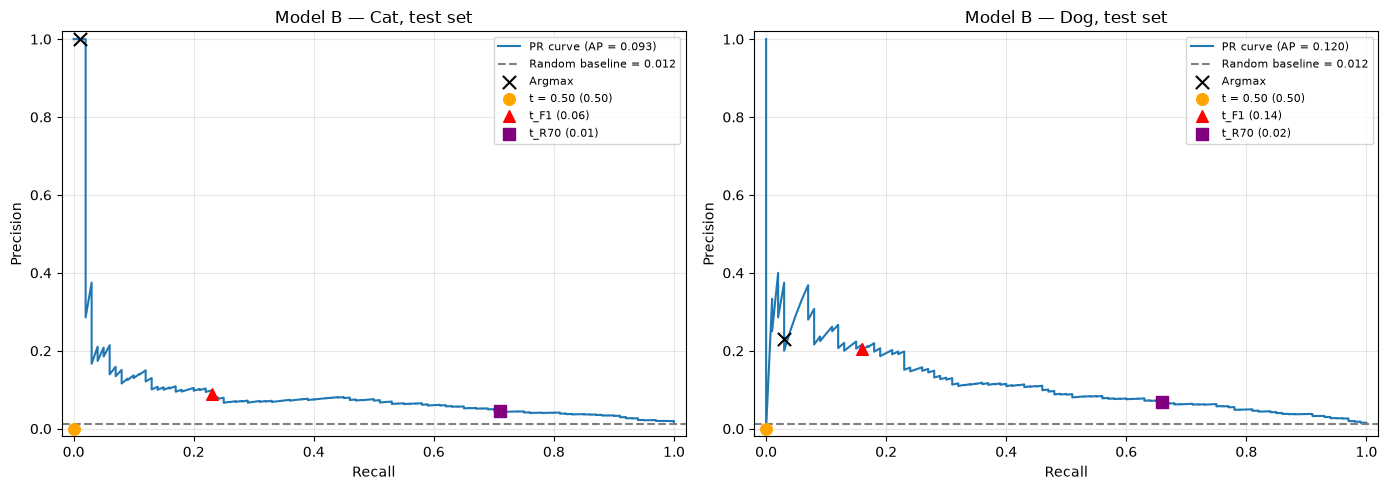

In [43]:
# TODO: for best_model, plot the test PR curves for cat and for dog (two panels), with the AP in the legend
#       hint: sklearn.metrics.precision_recall_curve, or build the curve yourself from the sorted scores
# TODO: draw the random baseline (share of cats, or dogs, in the test set) as a horizontal line
# TODO: mark four operating points on each curve: argmax (from the confusion matrix), t = 0.5, t_F1 and t_R70
from sklearn.metrics import precision_recall_curve

best_name = "Model A" if best_model is model_a else "Model B"
test_data = test_results[best_name]

true_labels = test_data["true_labels"]
probabilities = test_data["probabilities"]
metrics = test_data["metrics"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, c, name in zip(axes, [3, 5], ["Cat", "Dog"]):
    is_positive = true_labels == c
    scores = probabilities[:, c]

    # PR-кривая на test set.
    precision, recall, _ = precision_recall_curve(
        is_positive.numpy(),
        scores.numpy(),
    )

    ap = test_data["ap"][c]
    ax.plot(recall, precision, label=f"PR curve (AP = {ap:.3f})")

    # Доля настоящих представителей класса в test set.
    baseline = is_positive.float().mean().item()
    ax.axhline(
        baseline,
        color="gray",
        linestyle="--",
        label=f"Random baseline = {baseline:.3f}",
    )

    # Argmax: метрики из тестовой confusion matrix.
    ax.scatter(
        metrics["recall"][c].item(),
        metrics["precision"][c].item(),
        color="black",
        marker="x",
        s=90,
        label="Argmax",
        zorder=5,
    )

    # Пороги, выбранные на validation.
    operating_points = [
        (0.5, "t = 0.50", "orange", "o"),
        (results[c]["t_F1"], "t_F1", "red", "^"),
        (results[c]["t_R70"], "t_R70", "purple", "s"),
    ]

    for t, label, color, marker in operating_points:
        point_precision, point_recall, _ = prf_at_threshold(
            is_positive, scores, t
        )

        ax.scatter(
            point_recall,
            point_precision,
            color=color,
            marker=marker,
            s=70,
            label=f"{label} ({t:.2f})",
            zorder=4,
        )

    ax.set_title(f"{best_name} — {name}, test set")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

In [44]:
# TODO: for best_model, print one test table for cat and one for dog, one row per rule:
#       rule | t | images predicted positive | precision | recall | F1
#       rows: argmax, t = 0.5, t_F1, t_R70 (use the thresholds from section 7, do not tune them again)

best_name = "Model A" if best_model is model_a else "Model B"
test_data = test_results[best_name]

true_labels = test_data["true_labels"]
predicted_labels = test_data["predicted_labels"]
probabilities = test_data["probabilities"]
metrics = test_data["metrics"]

for c, name in [(3, "Cat"), (5, "Dog")]:
    is_positive = true_labels == c
    scores = probabilities[:, c]

    print(f"\n{best_name} — {name}, test set")
    print(
        f"{'Rule':10s} {'t':>6s} {'Predicted positive':>19s} "
        f"{'Precision':>10s} {'Recall':>8s} {'F1':>8s}"
    )

    # Argmax не использует фиксированный порог.
    count = (predicted_labels == c).sum().item()

    print(
        f"{'argmax':10s} {'—':>6s} {count:19d} "
        f"{metrics['precision'][c].item():10.3f} "
        f"{metrics['recall'][c].item():8.3f} "
        f"{metrics['f1'][c].item():8.3f}"
    )

    # Используем пороги, ранее выбранные на validation.
    rules = [
        ("t = 0.5", 0.5),
        ("t_F1", results[c]["t_F1"]),
        ("t_R70", results[c]["t_R70"]),
    ]

    for rule, t in rules:
        precision, recall, f1 = prf_at_threshold(is_positive, scores, t)
        count = (scores >= t).sum().item()

        print(
            f"{rule:10s} {t:6.2f} {count:19d} "
            f"{precision:10.3f} {recall:8.3f} {f1:8.3f}"
        )


Model B — Cat, test set
Rule            t  Predicted positive  Precision   Recall       F1
argmax          —                   1      1.000    0.010    0.020
t = 0.5      0.50                   0      0.000    0.000    0.000
t_F1         0.06                 261      0.088    0.230    0.127
t_R70        0.01                1546      0.046    0.710    0.086

Model B — Dog, test set
Rule            t  Predicted positive  Precision   Recall       F1
argmax          —                  13      0.231    0.030    0.053
t = 0.5      0.50                   1      0.000    0.000    0.000
t_F1         0.14                  78      0.205    0.160    0.180
t_R70        0.02                 975      0.068    0.660    0.123


#### Your answers: final metrics (explain properly)

1. Fill in for the test set: | Model | accuracy | macro F1 | weighted F1 | macro AP |. Which F1 is closer to accuracy, and why?
2. Explain each metric with your numbers. For the cat class of your best model, write one or two sentences for each of precision, recall, F1 and AP. Use counts from your test confusion matrix, for example: "Of the 80 images we predicted as cat, 30 were real cats, so precision = 30/80 = 0.38." (These numbers are made up, use yours.)
3. What does recall for cat and dog show that accuracy hides? How much accuracy would a model lose if it never predicted cat or dog at all?
4. Compute the random-baseline AP for cat and for airplane on the test set. Is your cat AP good or bad compared with its baseline? Why can the same AP value be good for one class and bad for another?
5. Changing `t` changed F1 for cat, but AP stayed the same. Why? When would you report AP, and when F1 at a chosen threshold?
6. Did Rule R70 still give recall ≥ 0.70 on the test set? Did Rule F1 give the best test F1 of the four rules? Explain any difference using what you know about the size of the validation set.
7. Did Dropout help on the test set? Compare Model A and Model B on macro F1, macro AP, and recall for cat and dog.
8. In the test confusion matrix of your best model, which classes are real cats most often predicted as? Does this make sense?

Write your answers here. A surprising result is fine if you explain it with your numbers.

**1. Test metrics**

| Model | Accuracy | Macro F1 | Weighted F1 | Macro AP |
|---|---:|---:|---:|---:|
| A — without Dropout | 0.639 | 0.548 | 0.636 | 0.590 |
| B — with Dropout | 0.684 | 0.560 | 0.675 | 0.635 |

Weighted F1 is closer to accuracy for both models because both give more influence to frequent classes. Macro F1 gives every class equal weight, so the poor results for cats and dogs reduce it much more.

**2. Cat metrics for our best model, Model B**

- **Precision:** Of the 1 image predicted as cat by argmax, 1 was a real cat, so precision = 1/1 = **1.000**. This perfect precision is based on only one prediction.
- **Recall:** Of the 100 real cats, only 1 was correctly identified, so recall = 1/100 = **0.010**. The model missed 99 cats.
- **F1:** With TP = 1, FP = 0 and FN = 99, F1 = 2TP/(2TP + FP + FN) = 2/101 ≈ **0.020**. Despite perfect precision, F1 is low because recall is extremely low.
- **AP:** Cat AP is **0.093**, calculated by averaging precision at the ranks occupied by real cats after sorting all test images by their cat scores. It measures ranking across thresholds, whereas the previous three values describe argmax predictions.

**3. What accuracy hides**

Model B achieves **68.4% accuracy**, but its recall is only **1% for cats** and **3% for dogs**. It correctly identifies just 4 of the 200 cats and dogs.

Cats and dogs together represent 200/8,200 ≈ **2.44%** of the test set. Therefore, missing all of them costs only 2.44 percentage points compared with classifying all of them correctly, with other outcomes unchanged. Relative to Model B’s current results, losing its four correct cat/dog predictions would reduce accuracy by only 4/8,200 ≈ **0.049 percentage points**, with other outcomes unchanged.

**4. Random-baseline AP**

The approximate random-baseline AP equals the class frequency:

- Cat: 100/8,200 ≈ **0.0122**.
- Airplane: 1,000/8,200 ≈ **0.1220**.

Model B’s cat AP of **0.093** is approximately **7.6 times** its baseline, so its ranking is better than random, although its absolute performance remains limited. The same AP of 0.093 would be below the airplane baseline: AP must be interpreted relative to how common the class is.

**5. Why F1 changes but AP stays the same**

Changing the threshold changes which images are predicted positive, so TP, FP, FN and F1 change. AP stays the same because the scores and their ranking remain unchanged.

We would report AP when comparing how well models rank images across thresholds. We would report precision, recall and F1 at a chosen threshold when describing the actual decisions an application will make.

**6. How the validation thresholds transferred to test**

Rule R70 achieved test recall of **0.710 for cats**, meeting the target, but only **0.660 for dogs**, missing it.

Rule F1 gave the highest test F1 among the four evaluated rules for both classes:

| Class | Argmax F1 | t = 0.5 F1 | Rule F1 | Rule R70 F1 |
|---|---:|---:|---:|---:|
| Cat | 0.020 | 0.000 | **0.127** | 0.086 |
| Dog | 0.053 | 0.000 | **0.180** | 0.123 |

Validation contained only **50 cats and 50 dogs**, so one additional detected animal changed validation recall by **2 percentage points**. Threshold selection is therefore sensitive to a few images, and validation performance does not guarantee identical test performance. We kept the validation thresholds unchanged.

**7. Did Dropout help?**

Dropout improved test macro F1 from **0.548 to 0.560** and macro AP from **0.590 to 0.635**. However, argmax recall decreased from **0.140 to 0.010 for cats** and from **0.140 to 0.030 for dogs**.

Thus, Dropout helped the overall metrics but reduced rare-class detection under argmax. Better macro AP does not guarantee better recall at a particular decision rule.

**8. Which classes were real cats confused with?**

Of the 100 real cats, Model B predicted **36 as frogs, 17 as deer and 16 as birds**. Only **1** was correctly predicted as cat.

Confusion with other animal classes is plausible because these small images can share colours, textures and backgrounds. However, the especially frequent cat-to-frog confusion suggests that the model learned insufficient features for recognising cats; the matrix alone cannot establish the exact visual cause.

## 9. Group contribution statement (required)

For each member, write what they did (e.g. data subsets, CNN design, training loop, Dropout experiment, metric functions, threshold search, plots, answers) and how the group used AI (what for, and how you checked it). Every member must still be able to explain the whole notebook.

| Student (full name) | Main contribution | How AI was used and checked |
|---|---|---|
|  |  |  |
|  |  |  |
|  |  |  |

## 10. Defense checklist and grading

Submit this completed notebook (or an HTML/PDF export with all cells and plots visible) before your defense. Each group has a short (~5 min) defense. Any member may be asked to:

- explain any line of your code: the subsets, every layer of your CNN, and the training steps
- show how the image shape changes through your CNN, and how you got the input size of the first `Linear` layer
- compute the number of parameters of one of your `Conv2d` layers by hand
- explain what Dropout does in train mode and in eval mode, and show the lines in your code where the mode is switched
- explain precision and recall for one class using a row and a column of your confusion matrix
- compute AP by hand for a short ranked list given by the instructor
- explain why the thresholds were chosen on the validation set and not on the test set, and what happens to precision and recall when `t` goes down
- explain why accuracy can look fine while the model fails on cats and dogs
- say what AI helped with and how you checked it

The Week 7 SIS mini-project is worth 4 points:

| Criterion | Full credit requires | Points |
|---|---|---|
| 1. Your CNN and training | Code written by the group runs from top to bottom. The three subsets match the table. The CNN follows every rule in section 2 and is built from PyTorch layers, not a ready-made or pretrained network. Model A and Model B differ only by Dropout. `model.train()` and `model.eval()` are used correctly. Both models are trained with the same settings, and the loss curves of both are plotted with the same y-axis range, a title, axis labels and a legend. | 1 |
| 2. Metrics and threshold search | Confusion matrix, per-class precision, recall, F1 and AP are computed by your own functions and match scikit-learn. The AP function gives 0.833 on the worked example. The best model and all four thresholds are chosen on the validation set only. Plots: confusion matrices with class names, precision/recall/F1 against `t`, and test PR curves with the random baseline and the four operating points. | 1 |
| 3. Explanations | All answer cells are filled in, correct, short, and use your own numbers: Dropout and train vs eval mode, each metric explained for the cat class, AP vs F1 and the random baseline, the threshold trade-off, and how the thresholds worked on the test set. | 1 |
| 4. Oral defense | Each member individually explains the group's code, plots and metrics (checklist above). | 1 |
| Total | | 4 |

How points are given:
- Criteria 1 to 3 are the same for the whole group. Criterion 4 is given to each student separately.
- A criterion that is mostly met, with one listed part missing or wrong, gets 0.5.
- If the test set was used to choose the model or a threshold, criterion 2 gets at most 0.5.
- If the CNN is a ready-made or pretrained network, criterion 1 gets 0.

Optional (no extra points):
- Class weights: pass `weight=` to `nn.CrossEntropyLoss` so rare classes count more (for example 10 for cat and dog, 1 for the rest). Train Model B again. Did recall for cat and dog go up? What happened to accuracy and to the best thresholds?
- ROC-AUC vs AP: for "cat vs not cat" on the test set, compute ROC-AUC with `sklearn.metrics.roc_auc_score` and plot the ROC curve with `sklearn.metrics.RocCurveDisplay`. A random model gets ROC-AUC 0.5 but AP equal to the share of cats. Why does ROC-AUC look much better than AP for a rare class?
- Rare vs hard: cats and dogs are hard classes even in normal, balanced CIFAR-10. How could you check how much of their low recall comes from having few training images, and how much from the classes being hard?
- Thresholds inside the 10-class classifier: predict cat if `p(cat) ≥ t_F1`, otherwise use argmax. What happens to accuracy and to the recall of the other classes?